# Figure comparaison — overshoot par habitant (CBA vs PBA)

Figure "Overshoot / Safe Operating Space" en valeurs **par habitant**, pour
tous les scénarios (base-year, 2019 France/World/Europe, scénarios de
transition 2050). Pour chaque scénario, 2 bulles par LP :
- bulle pleine : comptabilité **consommation** (CBA, `d_cba.pkl`)
- bulle hachurée : comptabilité **production** (PBA, `F_x_dom.pkl`, part domestique uniquement)

Génère `figures/overshoot_safe_operating_space_per_capita.png`.

Variante en valeurs absolues (1 bulle/scénario) : voir `Overshoot multi-scénarios.ipynb`.

In [2]:
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path

notebooks_dir = Path.cwd()
while not (notebooks_dir / "planefr_lib").exists() and notebooks_dir != notebooks_dir.parent:
    notebooks_dir = notebooks_dir.parent
if str(notebooks_dir) not in sys.path:
    sys.path.insert(0, str(notebooks_dir))

import matplotlib.pyplot as plt

from planefr_lib import config, io, processing
from planefr_lib.plot_overshoot import create_overshoot_safe_space_figure, create_overshoot_safe_space_figure_by_region

Failed to read module file 'c:\Users\Arnaud\AppData\Local\Programs\Python\Python314\Lib\urllib\parse.py' for module 'urllib.parse': UnicodeDecodeError
Traceback (most recent call last):
  File "C:\Users\Arnaud\AppData\Roaming\Python\Python314\site-packages\IPython\core\extensions.py", line 62, in load_extension
    return self._load_extension(module_str)
           ~~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^
  File "C:\Users\Arnaud\AppData\Roaming\Python\Python314\site-packages\IPython\core\extensions.py", line 77, in _load_extension
    mod = import_module(module_str)
  File "c:\Users\Arnaud\AppData\Local\Programs\Python\Python314\Lib\importlib\__init__.py", line 88, in import_module
    return _bootstrap._gcd_import(name[level:], package, level)
           ~~~~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "<frozen importlib._bootstrap>", line 1398, in _gcd_import
  File "<frozen importlib._bootstrap>", line 1371, in _find_and_load
  File "<frozen importlib._bootstrap>", line 1335, in 

## 1. Chargement des données et calcul par habitant

In [3]:
facteurs_carac_df = io.load_facteurs_carac()
seuils_df = io.load_seuils()
pop_df = io.load_population_df()

# Contrairement aux autres notebooks : inclut aussi les dossiers 2019_France /
# 2019_World / 2019_Europe_27, pour comparer les géographies en plus des scénarios.
scenario_folders = config.get_scenario_folders(exclude_2019=False, exclude_others=True)
scenario_names = [f.name for f in scenario_folders]
print(f"Scénarios trouvés ({len(scenario_folders)}): {scenario_names}")

Scénarios trouvés (4): ['2019_EU27', '2019_FR', '2019_W', '2019_WF']


c:\Users\Arnaud\Documents\CIRED\PlaneFR\Code\Module_PlaneFR\notebooks\planefr_lib\config.py:119: UserWarning: Le groupe 'no_SSP' ne contient pas Base_year_2015 : le scénario de référence (REFERENCE_SCENARIO_IDX) sera le premier par ordre alphabétique.
  warnings.warn(


In [4]:
all_scenarios_data = []
for scenario_folder in scenario_folders:
    print(f"Traitement : {scenario_folder.name}")
    data = processing.process_scenario_per_capita(scenario_folder, facteurs_carac_df, seuils_df, pop_df)
    print(f"  Sous-processus calculés : {list(data.keys())}")
    all_scenarios_data.append(data)

print(f"\n{len(all_scenarios_data)} scénarios traités.")

Traitement : 2019_EU27
  Sous-processus calculés : ['N surplus', 'P surplus', 'Blue water consumption', 'Cropland use', 'Agricultural land', 'GHG emissions', 'Biodiversity loss - PDF', 'Biodiversity loss - HANPP', 'Raw material consumption']
Traitement : 2019_FR
  Sous-processus calculés : ['N surplus', 'P surplus', 'Blue water consumption', 'Cropland use', 'Agricultural land', 'GHG emissions', 'Biodiversity loss - PDF', 'Biodiversity loss - HANPP', 'Raw material consumption']
Traitement : 2019_W
  Sous-processus calculés : ['N surplus', 'P surplus', 'Blue water consumption', 'Cropland use', 'Agricultural land', 'GHG emissions', 'Biodiversity loss - PDF', 'Biodiversity loss - HANPP', 'Raw material consumption']
Traitement : 2019_WF
  Sous-processus calculés : ['N surplus', 'P surplus', 'Blue water consumption', 'Cropland use', 'Agricultural land', 'GHG emissions', 'Biodiversity loss - PDF', 'Biodiversity loss - HANPP', 'Raw material consumption']

4 scénarios traités.


## 2. Figure overshoot en valeurs absolues, par pays/région (budget EPC)

Variante en valeurs absolues (rien n'est divisé par la population) : le budget
de chaque scénario est le budget mondial multiplié par sa part dans
`budget_shares.xlsx` (colonne "Part EPC ref.", ligne du code EXIOBASE déduit du
nom de dossier). Voir `create_overshoot_safe_space_figure_by_region`.

c:\Users\Arnaud\Documents\CIRED\PlaneFR\Code\Module_PlaneFR\notebooks\planefr_lib\plot_overshoot.py:1304: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[left_rect, 0.06, 0.98, top_rect])


Figure sauvegardée : C:\Users\Arnaud\Documents\CIRED\PlaneFR\Code\Module_PlaneFR\figures\overshoot_safe_operating_space_by_region.png


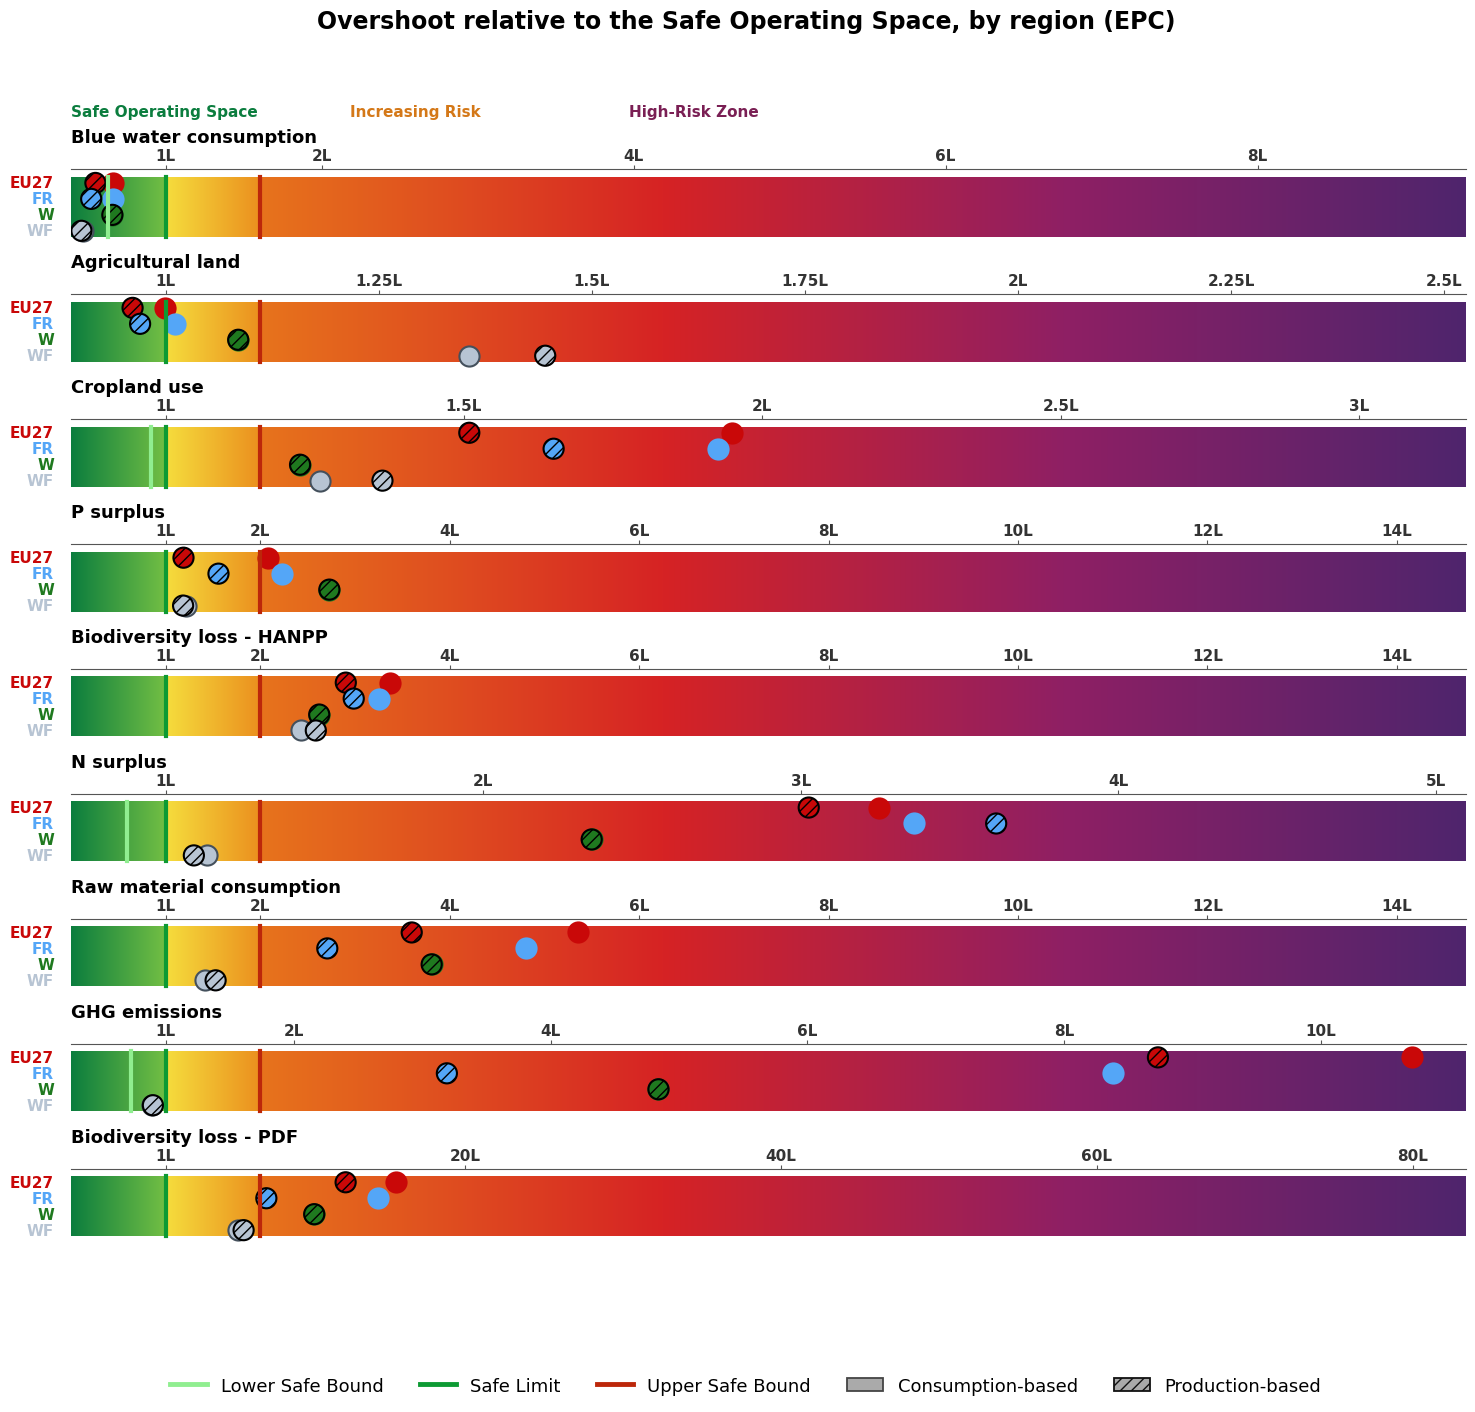

In [13]:
shares_df = io.load_budget_shares_df()
data_absolute = [processing.process_scenario_absolute(f, facteurs_carac_df, seuils_df) for f in scenario_folders]

fig = create_overshoot_safe_space_figure_by_region(
    all_scenarios_data=data_absolute, seuils_df=seuils_df, shares_df=shares_df,
    scenario_names=scenario_names,
    x_main_max=6, show_value_bounds=False, show_pba=True,
    show_value_overshoot=True, title_above_bar=True,
    title="Overshoot relative to the Safe Operating Space, by region (EPC)",
    sharing_principle="EPC", sensitivity=False, scale_UB =True,
    pop_df=pop_df,  # sensibilité de W : limite par habitant selon la période de population
)

config.FIGURES_DIR.mkdir(parents=True, exist_ok=True)
output_path = config.FIGURES_DIR / "overshoot_safe_operating_space_by_region.png"
fig.savefig(output_path, dpi=300, bbox_inches="tight")
print(f"Figure sauvegardée : {output_path}")
plt.show()